# 04 · Exploratory data analysis
Re-creates the figures with `scripts/exploratory_analysis.py` and shows each with its interpretation.
**All patterns describe the synthetic generator's assumptions, not real pumps.**

In [1]:
import sys, pandas as pd
from IPython.display import Image, Markdown, display
sys.path.insert(0, "../scripts")
pd.set_option("display.max_columns", 40); pd.set_option("display.width", 200)
import exploratory_analysis as eda
df, raw = eda.load()
eda.FIGS.clear()
eda.fig_fault_distribution(df); eda.fig_severity(df); eda.fig_sensor_distributions(df)
eda.fig_missing(df, raw); eda.fig_correlation(df); eda.fig_vibration_bearing(df); eda.fig_flow_pressure(df)
print(len(eda.FIGS), "figures so far")

7 figures so far


### Fault distribution

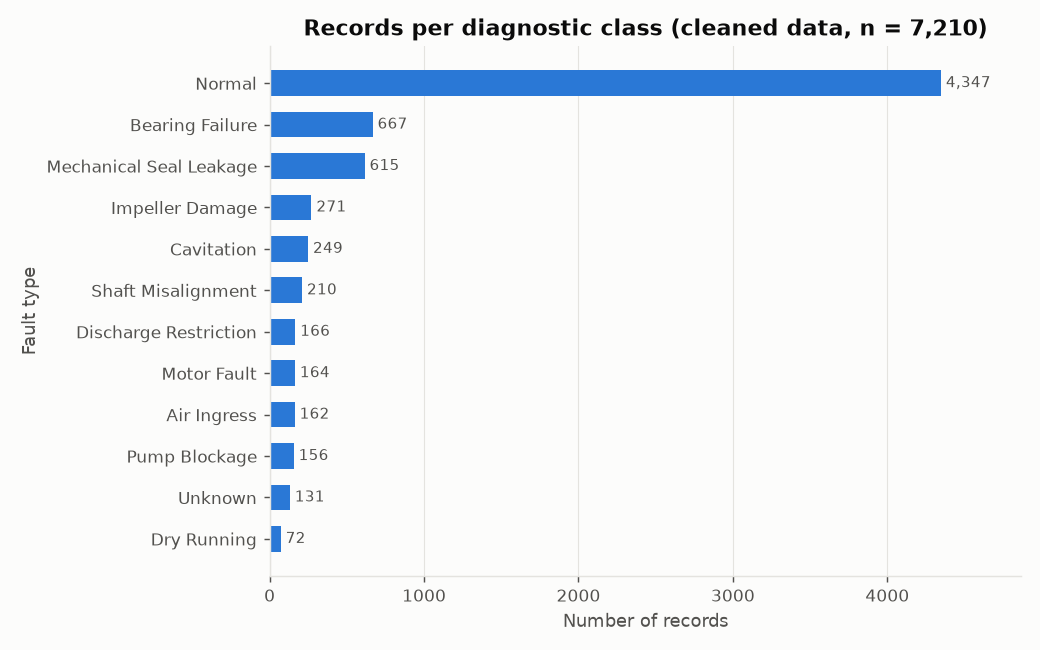

60% of records are Normal and 131 (1.8%) are Unknown. Among faults, **Bearing Failure** (667) and the next most common classes are wear-related; **Dry Running** is rarest (72). The classes are imbalanced (largest/smallest fault ratio 9.3:1), so any accuracy figure computed on this data must be reported per class, not only overall. The mix reflects the generator's chosen fault frequencies, not real failure statistics.

### Fault severity distribution

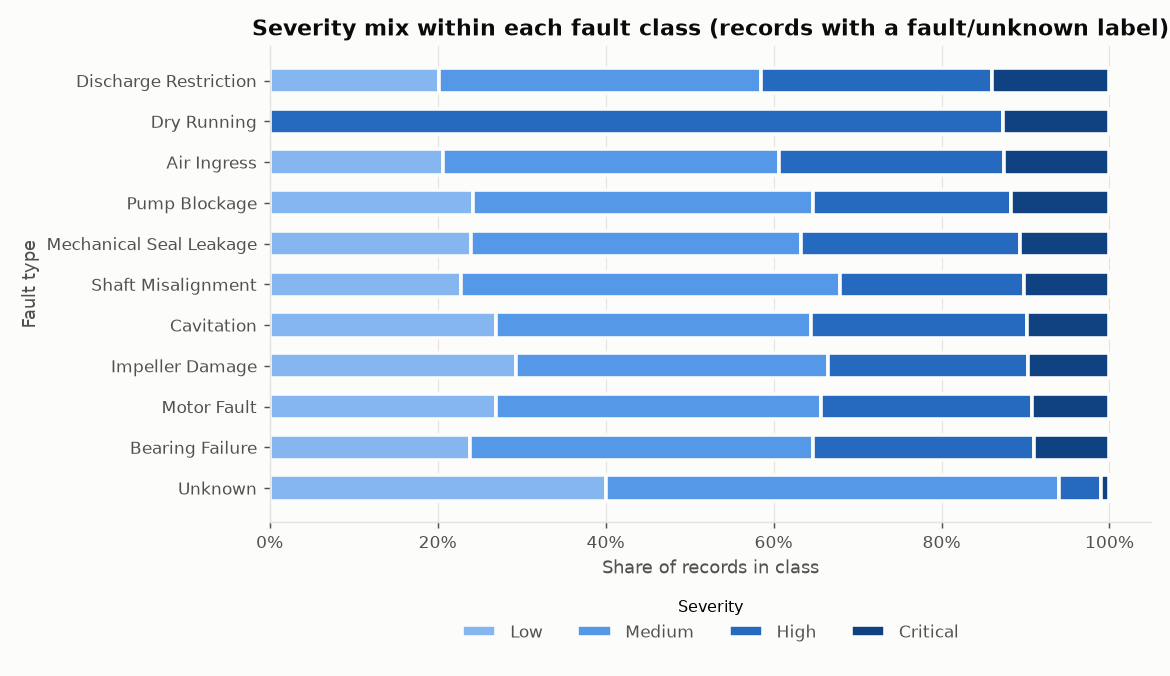

Dry Running has the highest Critical share (13%) — consistent with it being the only fault classed CRITICAL in the existing KBS. Most other faults spread over all levels because records follow a fault from first detection (Low) to repair (High/Critical). Unknown records are only Low/Medium. 43 fault records have severity 'Unknown' (missing in source) and are excluded from the bars.

### Sensor measurement distributions

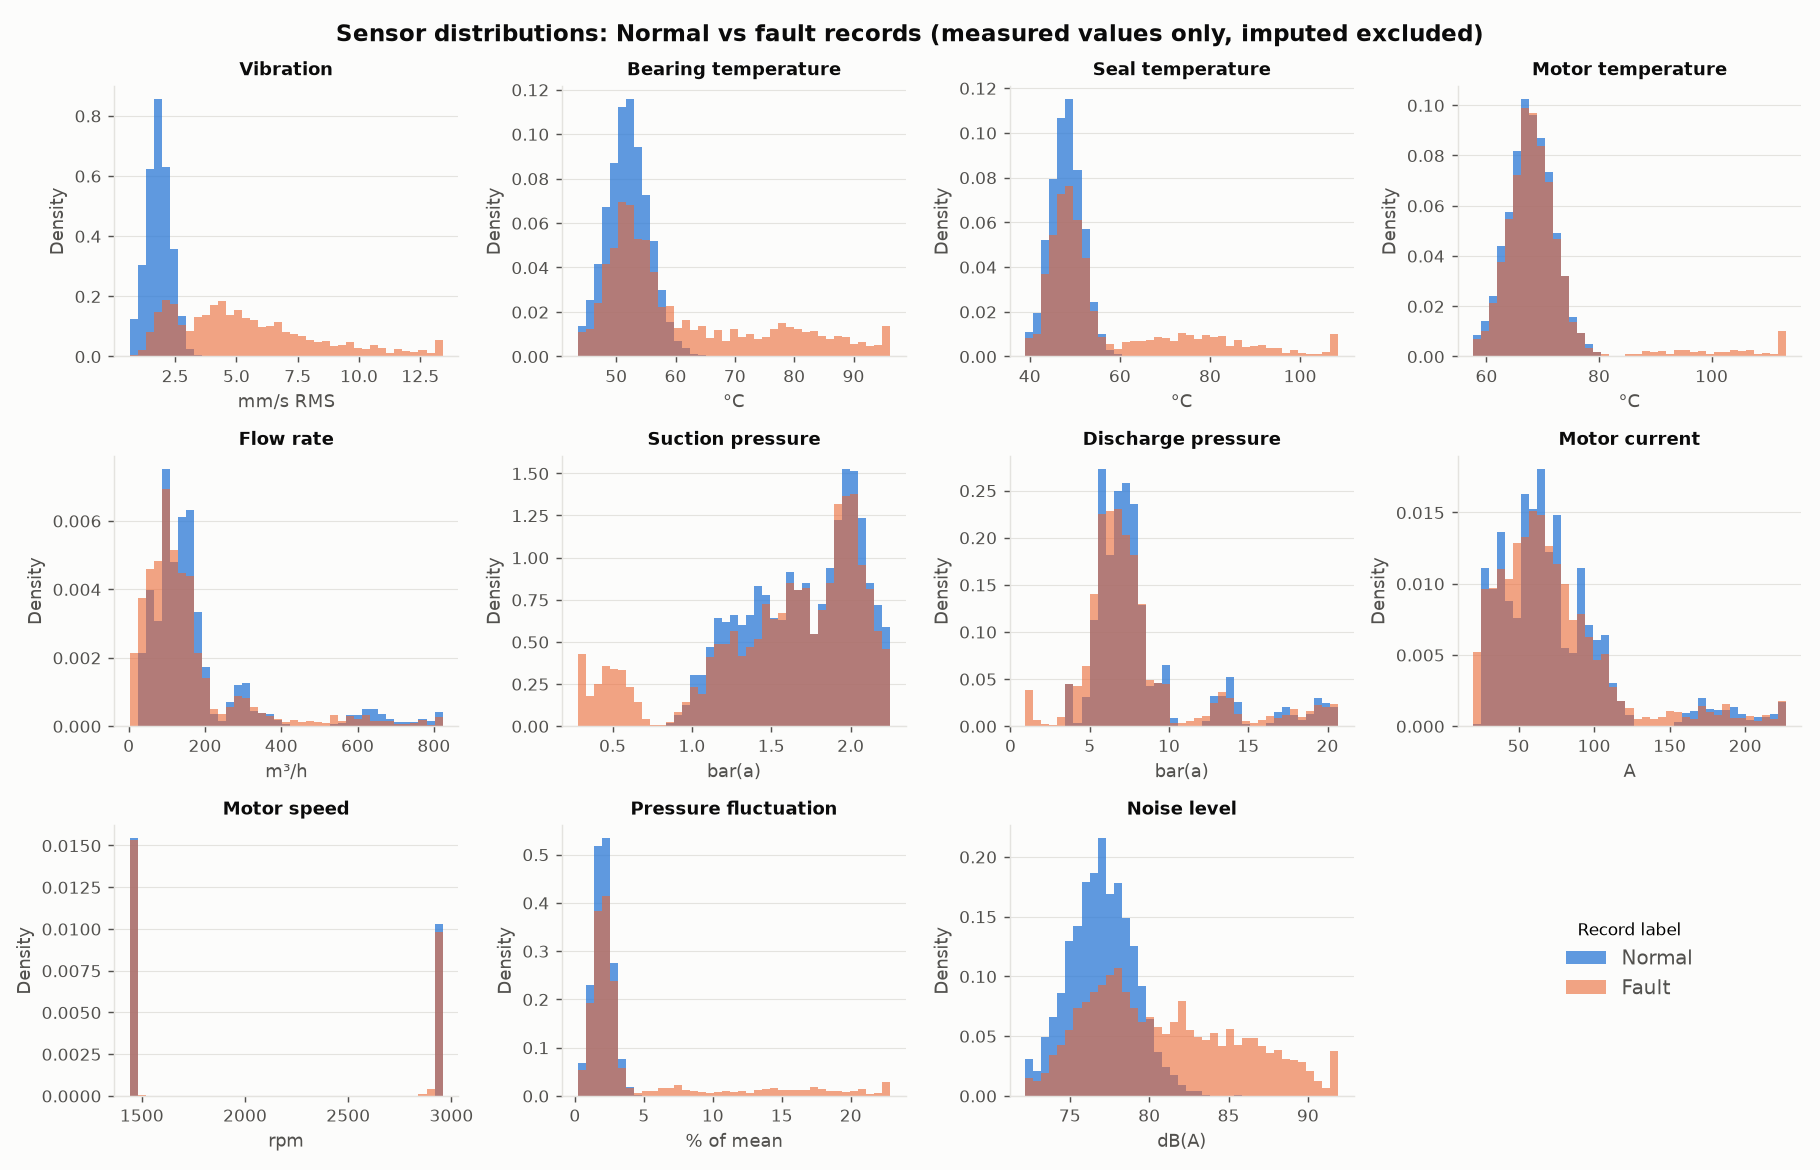

Normal records form narrow single peaks; fault records add long right tails for vibration, temperatures, pressure fluctuation and noise, and left tails for flow and suction pressure. Flow, discharge pressure and current are multimodal even for Normal records because the fleet mixes pump sizes — the reason preprocessing converts them to % of rating. Speed clusters at ≈1475 and ≈2950 rpm (4- and 2-pole motors).

| sensor | unit | normal median | fault median | fault skew |
|---|---|---|---|---|
| Vibration_mm_s | mm/s RMS | 1.82 | 4.79 | 0.91 |
| Bearing_Temperature_C | °C | 51.90 | 55.30 | 1.04 |
| Seal_Temperature_C | °C | 48.10 | 50.30 | 1.54 |
| Motor_Temperature_C | °C | 67.90 | 68.40 | 3.24 |
| Flow_Rate | m³/h | 137.30 | 114.50 | 2.40 |
| Suction_Pressure | bar(a) | 1.74 | 1.69 | -0.99 |
| Discharge_Pressure | bar(a) | 7.15 | 6.91 | 1.74 |
| Motor_Current | A | 65.50 | 65.05 | 1.70 |
| Motor_Speed_RPM | rpm | 1477.00 | 1477.00 | 0.40 |
| Pressure_Fluctuation | % of mean | 2.00 | 2.30 | 2.13 |
| Noise_Level | dB(A) | 77.00 | 80.10 | 0.46 |

### Missing-value visualisation

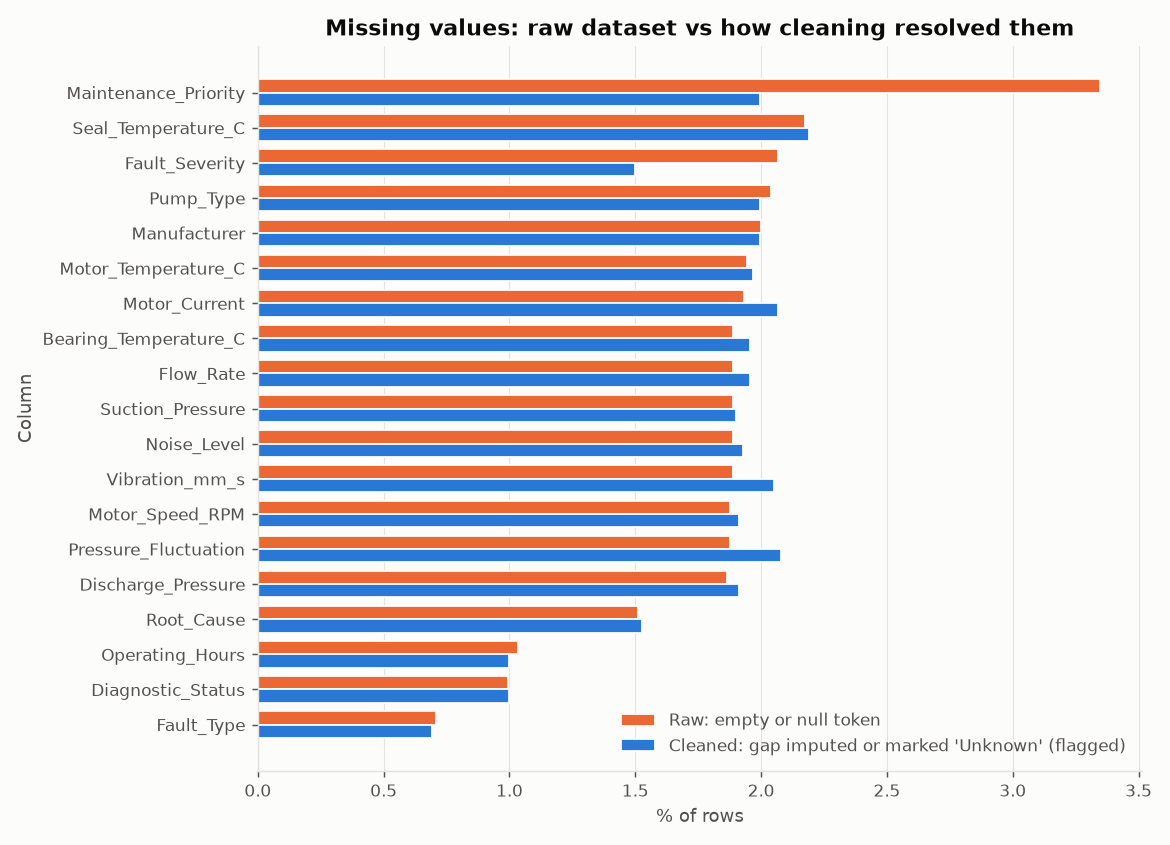

Raw missingness in sensor columns is ~1.9% each (random gaps plus seal-temperature sensor outages on P-007 and P-023). After cleaning **no sensor value is missing**: each gap is per-pump-median imputed and flagged. Sensor 'resolved' bars are slightly above raw because implausible values and suspected entry errors were also nullified and then imputed. Missing diagnostic fields became explicit 'Unknown' (or a logically implied value) instead of being guessed. Fault_Severity and Maintenance_Priority resolve *fewer* gaps than the raw bar suggests because raw tokens such as 'N/A', '0', '-' turned out to be valid codes for 'No Fault' / 'Not Applicable'. Maintenance date, downtime and cost are omitted: they are empty by design when no maintenance event occurred.

| column | raw missing % | cleaned: gap resolved (flagged) % | cleaned: still missing % |
|---|---|---|---|
| Maintenance_Priority | 3.35 | 2.00 | 0.00 |
| Seal_Temperature_C | 2.18 | 2.19 | 0.00 |
| Fault_Severity | 2.07 | 1.50 | 0.00 |
| Pump_Type | 2.04 | 2.00 | 0.00 |
| Manufacturer | 2.00 | 2.00 | 0.00 |
| Motor_Temperature_C | 1.94 | 1.97 | 0.00 |
| Motor_Current | 1.93 | 2.07 | 0.00 |
| Vibration_mm_s | 1.89 | 2.05 | 0.00 |
| Noise_Level | 1.89 | 1.93 | 0.00 |
| Suction_Pressure | 1.89 | 1.90 | 0.00 |
| Flow_Rate | 1.89 | 1.96 | 0.00 |
| Bearing_Temperature_C | 1.89 | 1.96 | 0.00 |
| Motor_Speed_RPM | 1.88 | 1.91 | 0.00 |
| Pressure_Fluctuation | 1.88 | 2.08 | 0.00 |
| Discharge_Pressure | 1.86 | 1.91 | 0.00 |
| Root_Cause | 1.51 | 1.53 | 0.00 |
| Operating_Hours | 1.03 | 1.00 | 0.00 |
| Diagnostic_Status | 0.99 | 1.00 | 0.00 |
| Fault_Type | 0.71 | 0.69 | 0.00 |

### Correlation heatmap

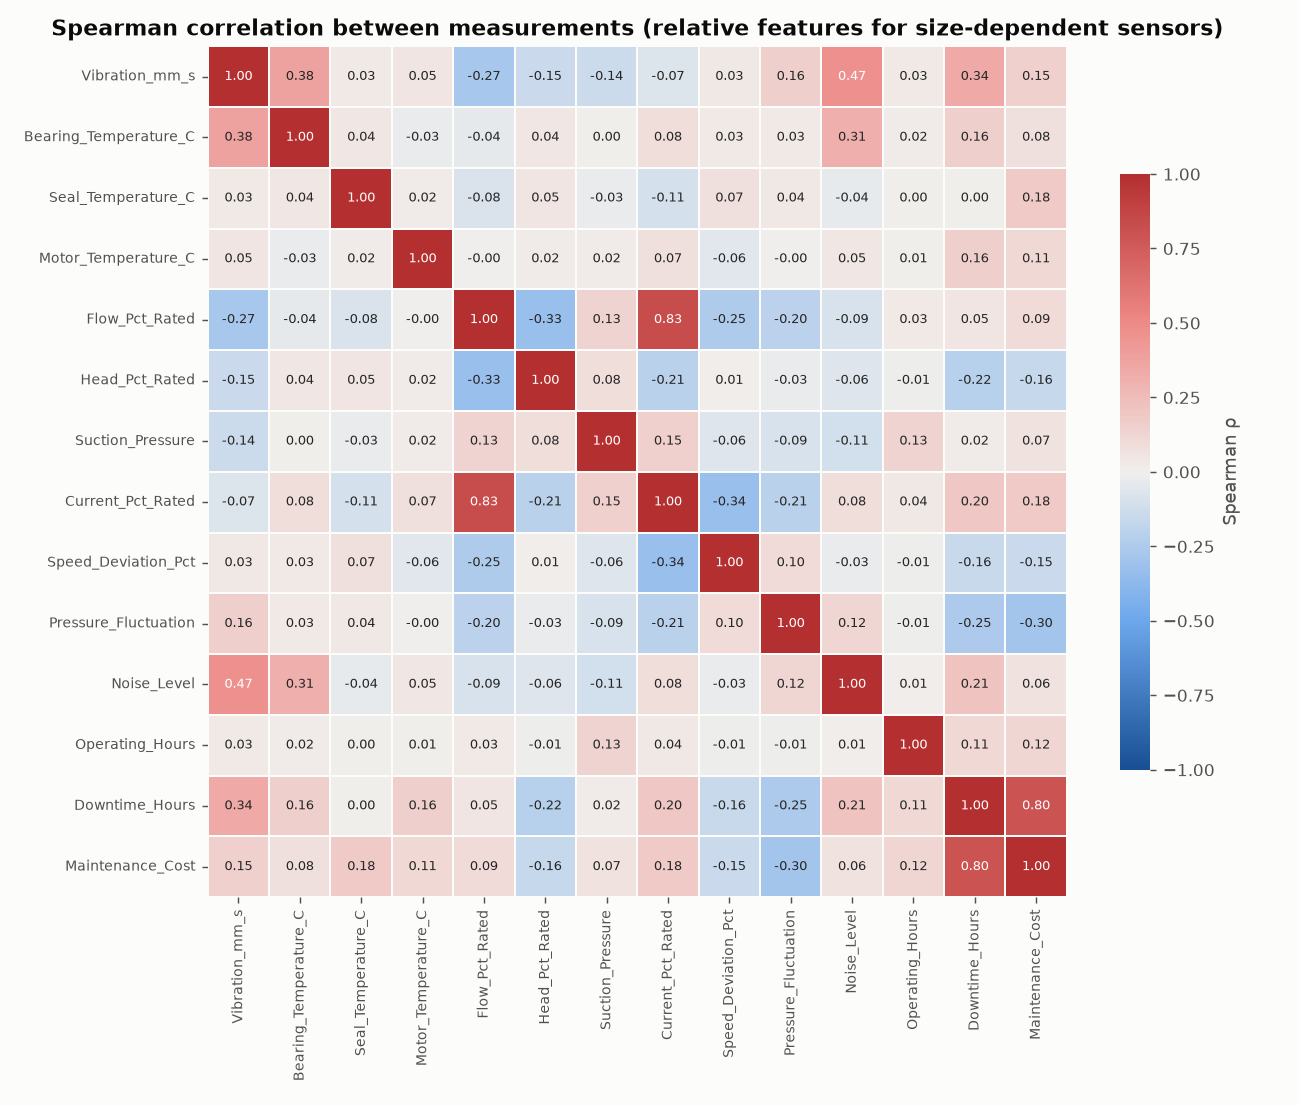

Spearman (rank) correlation is used because fault-driven distributions are heavily skewed. Size-dependent sensors are shown as % of rating; otherwise pump size dominates every correlation. Strongest pairs:

| A | B | ρ |
|---|---|---|
| Flow_Pct_Rated | Current_Pct_Rated | 0.83 |
| Downtime_Hours | Maintenance_Cost | 0.80 |
| Vibration_mm_s | Noise_Level | 0.47 |
| Vibration_mm_s | Bearing_Temperature_C | 0.38 |
| Vibration_mm_s | Downtime_Hours | 0.34 |
| Current_Pct_Rated | Speed_Deviation_Pct | -0.34 |

Correlations here mostly encode **shared faults** (e.g. cavitation lowers suction pressure and raises noise together). They are not causal relationships and must not be turned directly into rules.

### Vibration vs bearing temperature

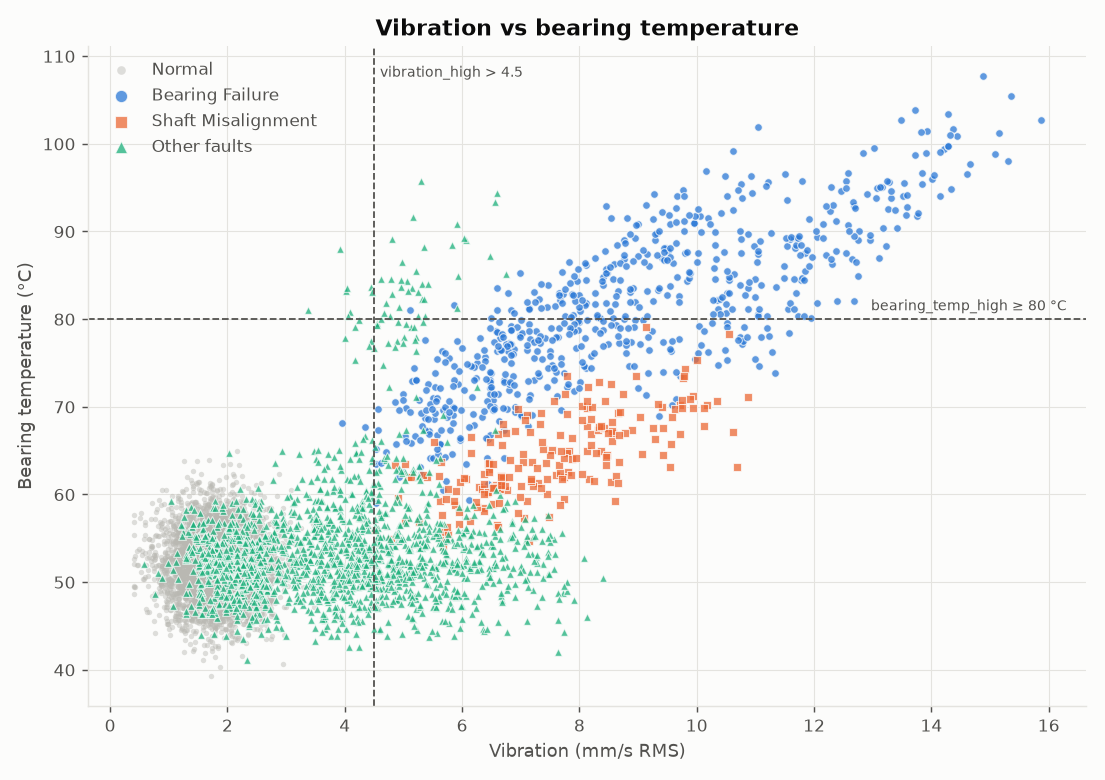

Bearing failures occupy the high-vibration / high-temperature quadrant (50% of them exceed both thresholds), while misalignment produces high vibration with only moderate heating (0% exceed both). Vibration alone cannot separate the two — the temperature axis (or a coupling-vibration observation) is what discriminates them. This supports a compound rule such as the existing KBS rule R01, but the separation is a property of the synthetic generator and needs field confirmation.

### Flow rate vs pressure

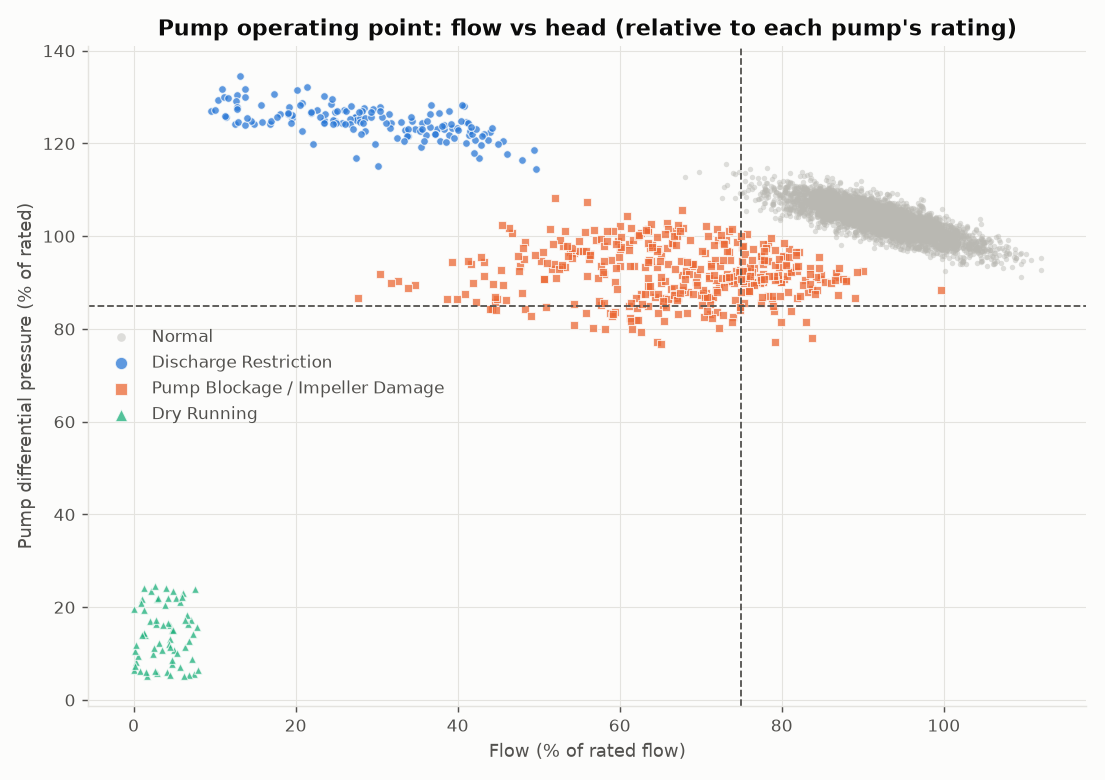

Normal records sit on a tight diagonal band (≈80–110 % flow, ≈95–110 % head) — the pump curve, where head falls as flow rises. Discharge restriction moves *up and left* along the curve (median flow 29 %, head 125 %): less flow but higher pressure. Blockage/impeller damage moves *down and left* (less flow **and** less head), and dry running collapses to near-zero flow and head. Low flow alone is therefore ambiguous; the direction of the head change separates the hypotheses — a relationship the current KBS cannot use because its thresholds are absolute (bar) not relative.

In [2]:
for fname, title, text in eda.FIGS:
    display(Markdown(f"### {title}"), Image(f"../visualizations/{fname}"), Markdown(text))

Downtime, cost, operating hours, outliers and symptoms:

### Downtime by fault type (corrective maintenance events)

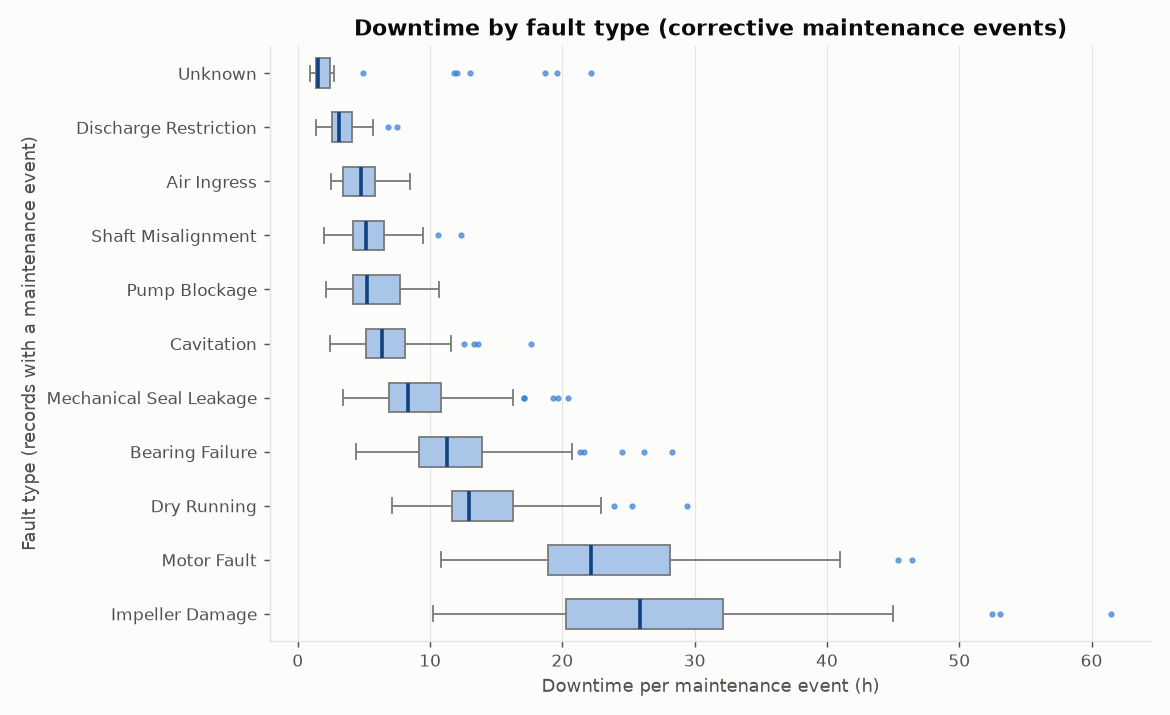



| Fault_Type | count | median | max |
|---|---|---|---|
| Impeller Damage | 102 | 25.9 | 61.5 |
| Motor Fault | 63 | 22.2 | 46.4 |
| Dry Running | 48 | 12.9 | 29.4 |
| Bearing Failure | 251 | 11.3 | 28.3 |
| Mechanical Seal Leakage | 221 | 8.3 | 20.4 |
| Cavitation | 86 | 6.4 | 17.6 |
| Pump Blockage | 49 | 5.2 | 10.7 |
| Shaft Misalignment | 76 | 5.2 | 12.3 |
| Air Ingress | 59 | 4.8 | 8.5 |
| Discharge Restriction | 56 | 3.2 | 7.5 |
| Unknown | 36 | 1.5 | 22.2 |

### Maintenance cost by fault type (corrective maintenance events)

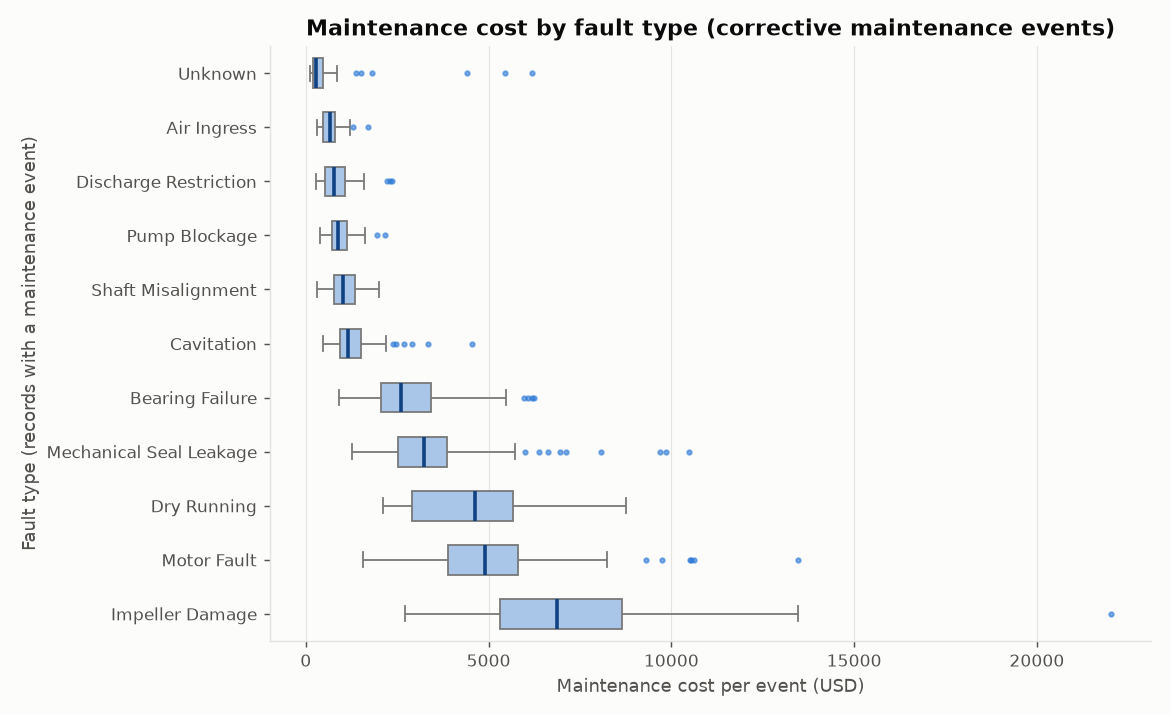



| Fault_Type | count | median | max |
|---|---|---|---|
| Impeller Damage | 102 | 6863.4 | 22038.1 |
| Motor Fault | 63 | 4905.7 | 13475.6 |
| Dry Running | 48 | 4622.7 | 8749.9 |
| Mechanical Seal Leakage | 221 | 3231.0 | 10480.5 |
| Bearing Failure | 251 | 2602.4 | 6234.2 |
| Cavitation | 86 | 1161.4 | 4540.6 |
| Shaft Misalignment | 76 | 1006.5 | 1992.8 |
| Pump Blockage | 49 | 889.8 | 2168.7 |
| Discharge Restriction | 56 | 784.5 | 2351.0 |
| Air Ingress | 59 | 665.2 | 1702.7 |
| Unknown | 36 | 285.6 | 6175.8 |

### Operating hours vs fault occurrence

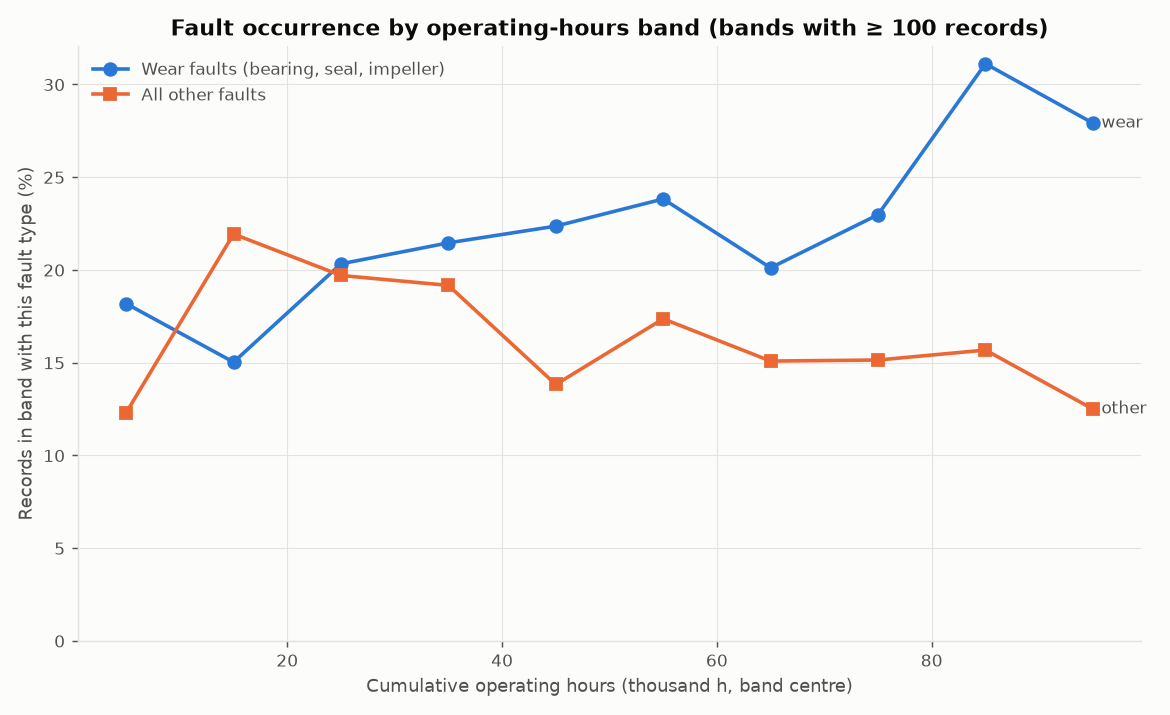

The share of wear-fault records rises from 18 % in the youngest band to 28 % in the oldest, while other faults stay roughly flat (12–22 %). **This trend was built into the generator** (wear-fault likelihood increases with running hours), so the chart verifies the simulation rather than discovering anything. With real data this is the analysis that would justify an age/hours factor in maintenance priority.

| band | n | wear | other |
|---|---|---|---|
| [0, 10000) | 187 | 0.182 | 0.123 |
| [10000, 20000) | 579 | 0.150 | 0.219 |
| [20000, 30000) | 797 | 0.203 | 0.197 |
| [30000, 40000) | 1221 | 0.215 | 0.192 |
| [40000, 50000) | 1382 | 0.224 | 0.138 |
| [50000, 60000) | 743 | 0.238 | 0.174 |
| [60000, 70000) | 716 | 0.201 | 0.151 |
| [70000, 80000) | 753 | 0.230 | 0.151 |
| [80000, 90000) | 421 | 0.311 | 0.157 |
| [90000, 100000) | 240 | 0.279 | 0.125 |

### Outlier analysis

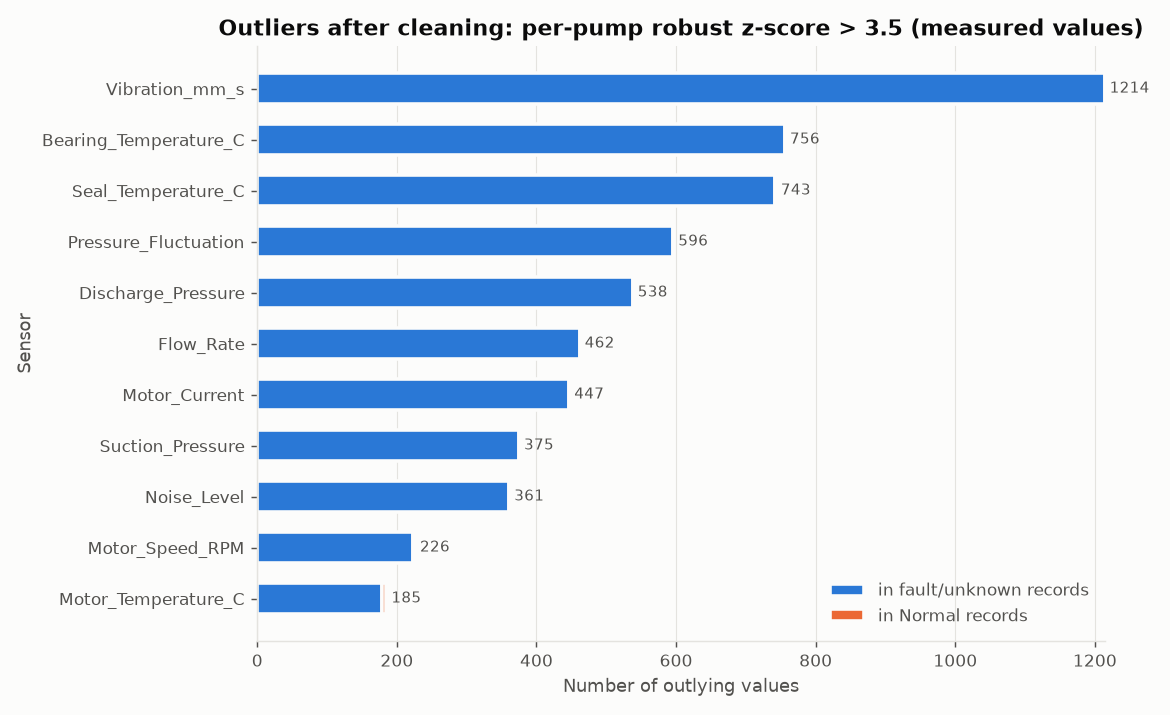

100% of the remaining outliers sit in fault/unknown records: they are fault signatures, which is why cleaning kept them. The remaining outliers in Normal records are mostly speed (tiny within-pump variance makes small deviations look extreme) and mild excursions; the gross entry errors were already nullified during cleaning.

| sensor | in fault/unknown records | in Normal records |
|---|---|---|
| Motor_Temperature_C | 178 | 7 |
| Motor_Speed_RPM | 223 | 3 |
| Noise_Level | 360 | 1 |
| Suction_Pressure | 375 | 0 |
| Motor_Current | 447 | 0 |
| Flow_Rate | 462 | 0 |
| Discharge_Pressure | 538 | 0 |
| Pressure_Fluctuation | 596 | 0 |
| Seal_Temperature_C | 742 | 1 |
| Bearing_Temperature_C | 756 | 0 |
| Vibration_mm_s | 1214 | 0 |

### Symptom frequency analysis

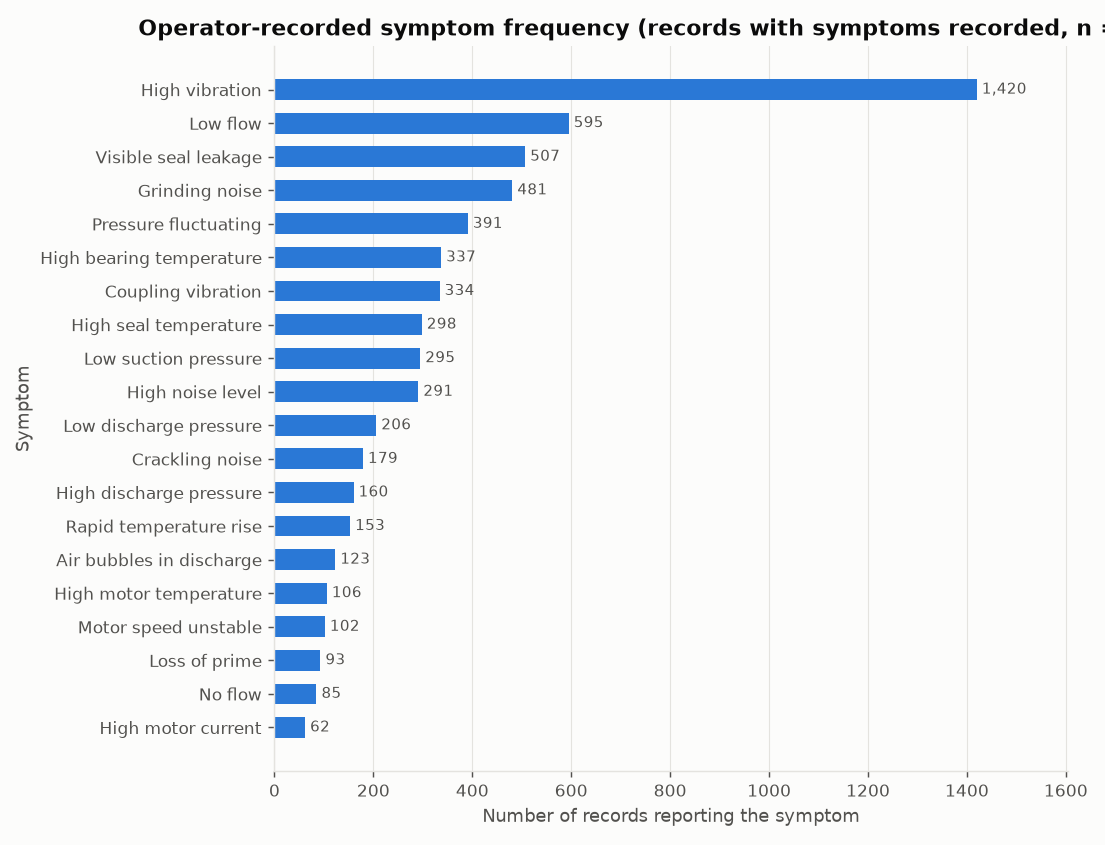

High vibration is by far the most reported symptom (1,420 records) but it occurs across many fault types, so it has low diagnostic specificity on its own. Rare symptoms such as air bubbles, loss of prime or speed instability are reported far less often but point to very few faults (see next figure) — they are high-value evidence for rules.

### Symptom–fault co-occurrence

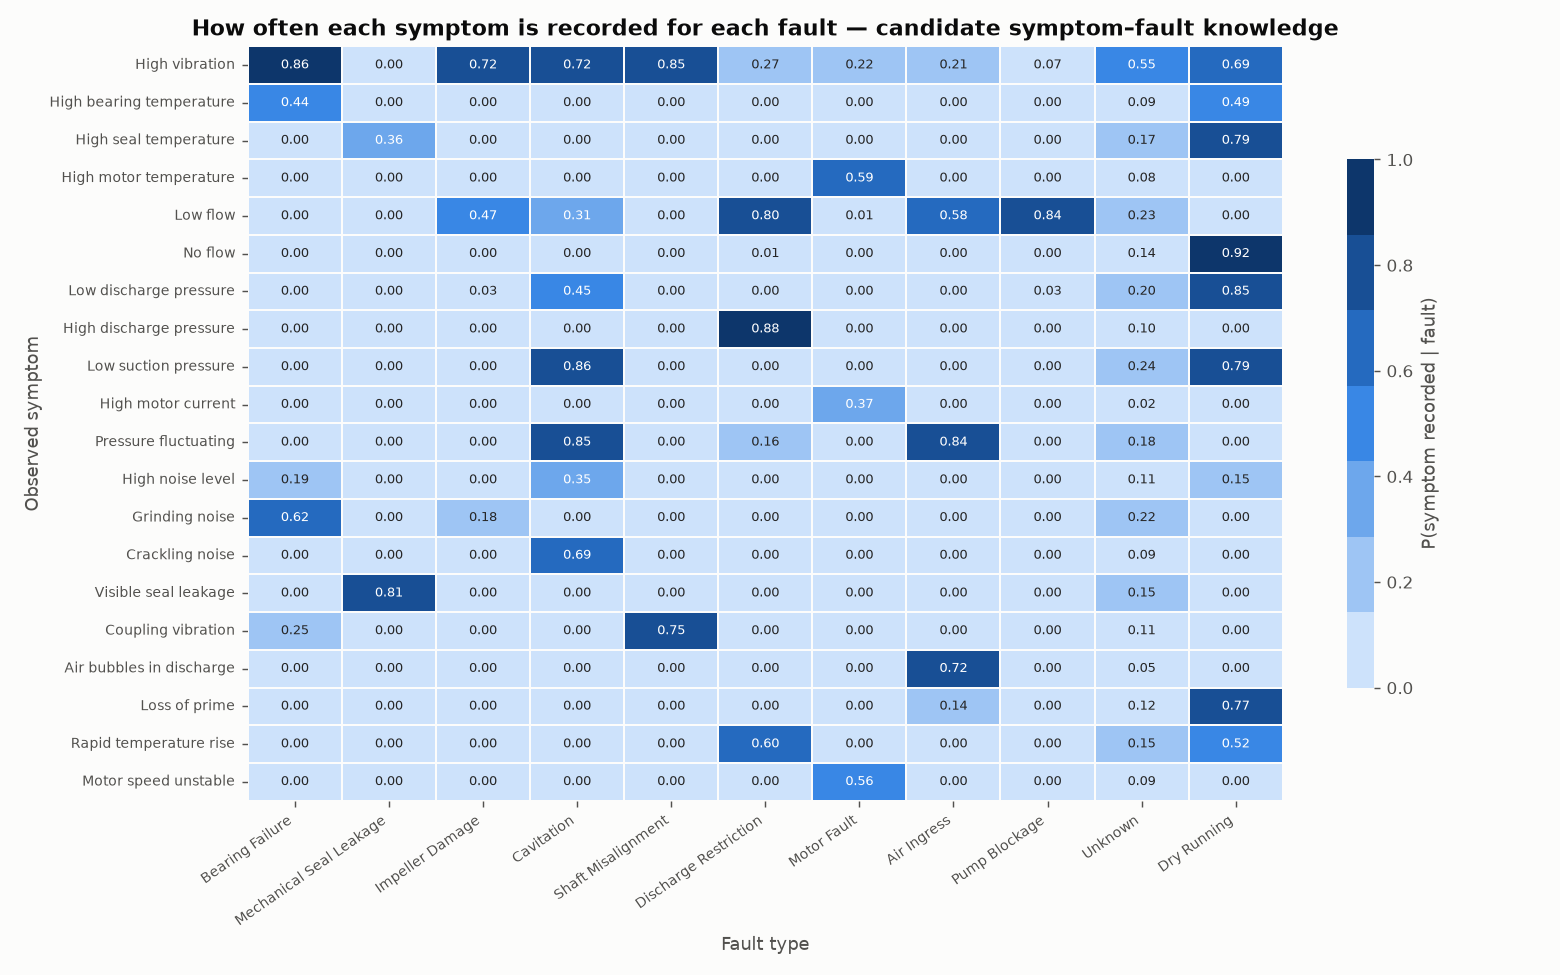

Each cell is the fraction of a fault's records in which the symptom was recorded. Strong, specific cells (e.g. seal leakage ↔ Mechanical Seal Leakage, crackling noise and low suction ↔ Cavitation, air bubbles ↔ Air Ingress, loss of prime/no flow ↔ Dry Running) correspond to the weighted links in `../data/symptom_fault_weights.csv`. This matrix is the bridge to knowledge acquisition: it can be used to **check** existing weights and to suggest candidates, but every candidate must be reviewed against domain sources — the probabilities here were produced by the generator's own assumptions.

| index | faults with P>0.5 |
|---|---|
| High vibration | 6 |
| High bearing temperature | 0 |
| High seal temperature | 1 |
| High motor temperature | 1 |
| Low flow | 3 |
| No flow | 1 |
| Low discharge pressure | 1 |
| High discharge pressure | 1 |
| Low suction pressure | 2 |
| High motor current | 0 |
| Pressure fluctuating | 2 |
| High noise level | 0 |
| Grinding noise | 1 |
| Crackling noise | 1 |
| Visible seal leakage | 1 |
| Coupling vibration | 1 |
| Air bubbles in discharge | 1 |
| Loss of prime | 1 |
| Rapid temperature rise | 2 |
| Motor speed unstable | 1 |

In [3]:
eda.FIGS.clear()
eda.box_by_fault(df, "Downtime_Hours", "Downtime per maintenance event (h)", "eda_08_fault_vs_downtime.png",
                 "Downtime by fault type (corrective maintenance events)", lambda m, pm: "")
eda.box_by_fault(df, "Maintenance_Cost", "Maintenance cost per event (USD)", "eda_09_fault_vs_cost.png",
                 "Maintenance cost by fault type (corrective maintenance events)", lambda m, pm: "")
eda.fig_hours(df); eda.fig_outliers(df); eda.fig_symptoms(df)
for fname, title, text in eda.FIGS:
    display(Markdown(f"### {title}"), Image(f"../visualizations/{fname}"), Markdown(text))

The complete interpretation (including the downtime/cost commentary) is in `reports/eda_report.md`.